# Issue #208 — dynamic N×K and risk-conditioned parlay policy frontier

Contract BJ-UNIFIED-DYNAMIC-N-001 / v4 (PI takeover 2026-08-15), generated from producer-code commit `3be8290292482e11db397dacd2b3fbb25026055e`. Primary candidate: per-issue learned action-value policy Q_theta(x,a) (MLPRegressor) on the bounded N×K×lane×capital catalog; controls = Ridge + best fixed action + state-conditioned restricted N/K/N×K policies; 16 preregistered hash seeds aggregated. Payout economics: pre-tax gross multiple = hit × 0.65 × product(official SP), coefficient applied exactly once per winning ticket. 2024/LOCKED_TEST outcomes remain embargoed. This executed notebook reads only the committed immutable package under `results/issue-208/`.

In [1]:
from pathlib import Path
import json
import pandas as pd

def _find_root():
    p = Path.cwd()
    for _ in range(6):
        if (p / "results" / "issue-208").exists():
            return p
        p = p.parent
    return Path.cwd()

ROOT = _find_root()
PACKAGE = ROOT / "results" / "issue-208"
import sys
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("package:", PACKAGE.resolve(), "exists:", PACKAGE.exists())

package: /home/drwho1985/.cache/codex-pi/bj208-complete/results/issue-208 exists: True


## 1. Data census

171 development issues (CV_2021 58 / CV_2022 58 / CV_2023 55) + 75 LOCKED_TEST (embargoed). Panels built from the frozen #205 value matrix (sha 8fdace9c…); upstream #207 manifest (48c11d97…) bound at load. The frozen incumbent path is reconstructed from #207 CONTROLLING ticket identities under the corrected payout economics: pre-tax gross multiple = hit × 0.65 × product(official SP) — the Beijing payout coefficient applied exactly once per winning N-fold ticket (PI 2026-08-15).

In [2]:
census = pd.read_csv(PACKAGE / "census.csv")
census.groupby("split").agg(issues=("issue", "nunique"), mean_M=("M", "mean")).round(1)

,issues,mean_M
split,,
CV_2021,58,321.1
CV_2022,58,285.8
CV_2023,55,283.5
LOCKED_TEST,75,226.2


## 2. Action frontier (counterfactual label surface)

CV_2021 fit fold surface: per-issue × 168 actions, seed-aggregated matched pre-tax capital lift vs frozen N7/K8 incumbent.

In [3]:
surface = pd.read_parquet(PACKAGE / "label_surface_fit.parquet")
print("surface rows:", len(surface))
surface.groupby(["lane", "capital"]).agg(actions=("action_key", "count"), mean_lift=("matched_lift_mean", "mean")).round(1)

surface rows: 9744


actions  mean_lift
lane        capital                          
LEARNED_MLP NATIVE_2_YUAN     1218       -1.4
            SIMPLE_ACTIVE     1218     -431.8
MARKET_WOR  NATIVE_2_YUAN     1218      -13.0
            SIMPLE_ACTIVE     1218     -767.4
MARKET_WR   NATIVE_2_YUAN     1218      -13.9
            SIMPLE_ACTIVE     1218     -777.2
VALUE_WOR   NATIVE_2_YUAN     1218      -16.3
            SIMPLE_ACTIVE     1218     -868.2

## 3. N×K performance surface (CV_2021 fit fold)

Median matched lift over lanes/capital, aggregated by N and K.

In [4]:
pivot = surface.pivot_table(index="n", columns="k", values="matched_lift_mean", aggfunc="median").round(1)
pivot

k,8,16,32
n,,,
4,0.0,-16.0,-48.0
5,0.0,-16.0,-48.0
6,0.0,-16.0,-48.0
7,0.0,-16.0,-48.0
8,0.0,-16.0,-48.0
9,-487.0,-495.0,-511.0
10,-487.0,-495.0,-511.0


## 4. Chronological learned policy (safety-gated)

Fold 1 (train CV_2021 → test CV_2022) and Fold 2 (train CV_2021+CV_2022 → test CV_2023). Chronological validation block = last 15% of train issues by issue id; sklearn row-level early stopping disabled (REWORK v2 / D3). All payouts use the corrected pre-tax economics (0.65 applied exactly once per winning ticket).

In [5]:
for fold in ("fold1", "fold2"):
    learned = pd.read_parquet(PACKAGE / f"path_learned_{fold}.parquet")
    print(fold, "ending:", round(float(learned.iloc[-1]["post_issue_bankroll_yuan"]), 2), "issues:", len(learned))
loss = pd.read_csv(PACKAGE / "chronological_train_val_loss.csv")
loss

fold1 ending: 99072.0 issues: 58
fold2 ending: 99245.38 issues: 55


,model,fit_issues,validation_issues,fit_rmse,validation_rmse
0,MLP,98,18,1282.954513,1016.481116


## 5. Controls / attribution matrix (CV_2023 test split)

All arms start ¥100,000. Payout economics use pre-tax gross multiple = hit × 0.65 × product(official SP), coefficient applied exactly once per winning ticket. `capital_change_identical` binds frozen #207 EQUAL_1PCT identities with the corrected multiples.

In [6]:
import glob
rows = []
for f in sorted(glob.glob(str(PACKAGE / "path_control_*_fold2.parquet"))):
    p = pd.read_parquet(f)
    name = Path(f).name.removeprefix("path_control_").removesuffix("_fold2.parquet")
    rows.append({"control": name, "ending_yuan": round(float(p.iloc[-1]["post_issue_bankroll_yuan"]), 2)})
pd.DataFrame(rows).sort_values("ending_yuan", ascending=False).reset_index(drop=True)

,control,ending_yuan
0,static_n8k8,100218.21
1,cash_no_bet,100000.00
2,fixed_n7_dynamic_k,99798.87
3,static_n5k8,99710.20
4,dynamic_n_fixed_k8_lane,99609.10
5,static_n4k8,99609.10
6,best_fixed_policy,99569.54
7,dynamic_nk_fixed_generator,99559.71
8,static_n9k8,99403.42
9,static_n6k8,99387.50


## 6. Learning diagnostics

The coarse calibration trend improves toward the highest predicted bin, but adjacent bins are not monotone and predicted/realized scales are mismatched. The conservative gate vetoes all 113 primary-policy executions, so learned path ≡ incumbent. This is a safe null result, not evidence that the neural policy improved the baseline.

In [7]:
calib = pd.read_csv(PACKAGE / "calibration_curve.csv")
calib.round(1)

,bin,predicted_best_lift,realized_best_lift,issues
0,0,-6.6,2215.1,24
1,1,54.2,1593.8,23
2,2,110.8,7388.3,23
3,3,166.0,5091.9,23
4,4,260.9,17332.8,23


In [8]:
freq = pd.read_csv(PACKAGE / "action_frequency.csv")
freq.head(6)

,action_key,n,k,lane,capital,count,share
0,N7/K8/MARKET_WOR/NATIVE_2_YUAN,7,8,MARKET_WOR,NATIVE_2_YUAN,113,1.0


In [9]:
fallback = pd.read_csv(PACKAGE / "ood_fallback_census.csv")
fallback

,split,issues,executed,fallback_incumbent,no_bet
0,CV_2022,58,0,58,58
1,CV_2023,55,0,55,55


## 7. Genuine dynamic controls

Each restricted control scores lawful actions separately for every issue from causal state. The resulting choices reveal model collapse: N-only selects N4 throughout; K-only selects K8 throughout; joint N×K varies N but keeps K8. Score variation therefore exists, but dynamic K behavior does not.

In [10]:
dynamic = pd.read_parquet(PACKAGE / "dynamic_control_decisions.parquet")
dynamic.groupby(["split", "policy", "n", "k"]).size().rename("issues").reset_index()

,split,policy,n,k,issues
0,CV_2022,dynamic_n_fixed_k8_lane,4,8,58
1,CV_2022,dynamic_nk_fixed_generator,4,8,53
2,CV_2022,dynamic_nk_fixed_generator,5,8,3
3,CV_2022,dynamic_nk_fixed_generator,6,8,2
4,CV_2022,fixed_n7_dynamic_k,7,8,58
5,CV_2023,dynamic_n_fixed_k8_lane,4,8,55
6,CV_2023,dynamic_nk_fixed_generator,4,8,43
7,CV_2023,dynamic_nk_fixed_generator,5,8,2
8,CV_2023,dynamic_nk_fixed_generator,6,8,2
9,CV_2023,dynamic_nk_fixed_generator,7,8,3


## 8. Issue-level equity paths and holding feasibility

Capital paths, rather than turnover ROI alone, are the primary view. Static N8 is positive only on CV_2023 and fails to replicate on CV_2022; cash is flat; learned is exactly the incumbent because every decision falls back.

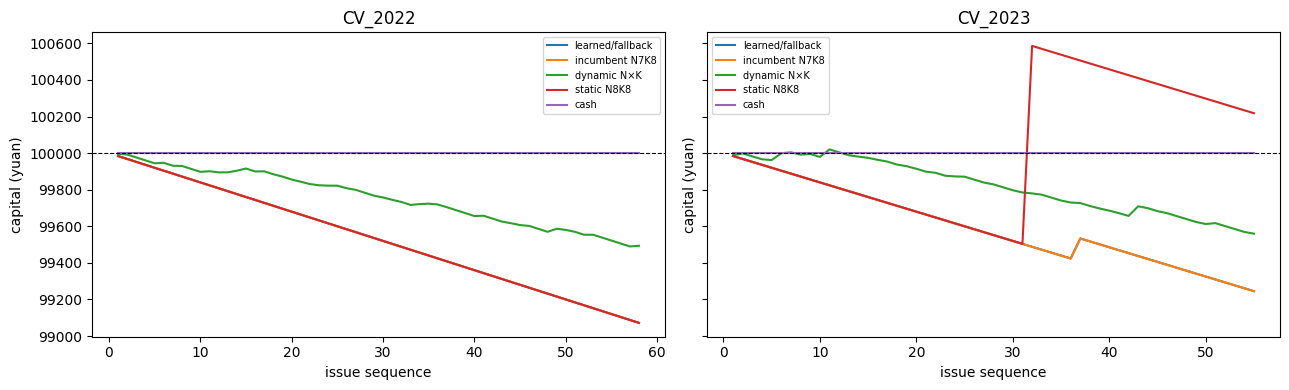

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (fold, split) in zip(axes, [("fold1", "CV_2022"), ("fold2", "CV_2023")]):
    paths = {
        "learned/fallback": PACKAGE / f"path_learned_{fold}.parquet",
        "incumbent N7K8": PACKAGE / f"path_control_incumbent_n7k8_{fold}.parquet",
        "dynamic N×K": PACKAGE / f"path_control_dynamic_nk_fixed_generator_{fold}.parquet",
        "static N8K8": PACKAGE / f"path_control_static_n8k8_{fold}.parquet",
        "cash": PACKAGE / f"path_control_cash_no_bet_{fold}.parquet",
    }
    for label, path in paths.items():
        frame = pd.read_parquet(path).sort_values(["year", "issue"])
        ax.plot(range(1, len(frame) + 1), frame["post_issue_bankroll_yuan"], label=label)
    ax.axhline(100_000, color="black", linewidth=0.8, linestyle="--")
    ax.set(title=split, xlabel="issue sequence", ylabel="capital (yuan)")
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

In [12]:
holding = pd.read_parquet(PACKAGE / "path_holding_metrics.parquet")
holding.loc[:, [
    "split", "policy", "ending_capital_yuan", "turnover_yuan",
    "active_support_roi", "max_drawdown_pct",
    "max_consecutive_losing_issues", "rolling5_loss_prob",
    "max_recovery_issues", "ex_largest_issue_ending_capital_yuan",
]].sort_values(["split", "ending_capital_yuan"], ascending=[True, False])

,split,policy,ending_capital_yuan,turnover_yuan,active_support_roi,max_drawdown_pct,max_consecutive_losing_issues,rolling5_loss_prob,max_recovery_issues,ex_largest_issue_ending_capital_yuan
4,CV_2022,cash_no_bet,100000.000000,0.0,NaN,0.000000,0.0,0.000000,0.0,100000.000000
6,CV_2022,dynamic_n_fixed_k8_lane,99515.496835,928.0,-0.522094,0.004881,16.0,0.962963,58.0,99531.496835
22,CV_2022,static_n4k8,99515.496835,928.0,-0.522094,0.004881,16.0,0.962963,58.0,99531.496835
0,CV_2022,best_fixed_policy,99514.729233,928.0,-0.522921,0.004937,10.0,0.925926,57.0,99530.729233
8,CV_2022,dynamic_nk_fixed_generator,99493.436272,928.0,-0.545866,0.005102,16.0,0.962963,58.0,99476.771197
24,CV_2022,static_n5k8,99428.023298,928.0,-0.616354,0.005805,20.0,0.925926,58.0,99388.579812
10,CV_2022,fixed_n7_dynamic_k,99303.851145,928.0,-0.750160,0.006961,25.0,0.907407,58.0,99237.133572
26,CV_2022,static_n6k8,99137.869292,928.0,-0.929020,0.008621,20.0,1.000000,58.0,99153.869292
12,CV_2022,generator_change_n7k8,99104.745737,928.0,-0.964714,0.008953,39.0,1.000000,58.0,99120.745737
14,CV_2022,incumbent_n7k8,99072.000000,928.0,-1.000000,0.009280,58.0,1.000000,58.0,99088.000000


## 9. Selection receipt and #209 handoff

Lexicographic rule over 2 constructible folds: learned matched lift = 0.0 on both folds (safety-gated to incumbent), so no row qualifies → freeze N7/K8/MARKET_WOR/native-¥2 incumbent. Handoff v4 carries fitted MLP weights + scaler and the canonical post-publication package path.

In [13]:
selection = json.loads((PACKAGE / "selection.json").read_text())
print("eligible:", selection["eligible"])
print("median matched lift:", selection["median_matched_lift_yuan"])
print("positive folds:", selection["positive_fold_count"], "/", selection["constructible_fold_count"])
print("frozen candidate:", selection["frozen_candidate"]["policy"])
handoff = json.loads((PACKAGE / "handoff_209.json").read_text())
print("handoff model_serialized:", handoff["model"].get("model_serialized"))
print("handoff scaler_mean present:", handoff["model"].get("scaler_mean") is not None)
print("handoff model_file:", handoff["model_file"])

eligible: False
median matched lift: 0.0
positive folds: 0 / 2
frozen candidate: FROZEN_N7_INCUMBENT
handoff model_serialized: True
handoff scaler_mean present: True
handoff model_file: results/issue-208/models/fold2_mlp.joblib


## 10. Package verification + tamper self-tests

The production verifier checks manifest/receipt/provenance/code binding, rich decision-critical schema, completion, actual-refit holdout evidence, REQ evidence paths, capital, N/K bundles, dynamic-control semantics, payout economics and final handoff. All 13 attacks must be detected.

In [14]:
from scripts.run_bj208_policy import verify_package

failures = verify_package(PACKAGE)
print("production verification failures:", failures if failures else "NONE")

production verification failures: NONE


In [15]:
tamper = json.loads((PACKAGE / "tamper_results.json").read_text())
for res in tamper:
    print(res["attack"], "->", "DETECTED" if res["detected"] else "MISSED", res["failures"][:1])

mutate_settlement -> DETECTED ['capital conservation violated on 1 rows']
self_consistent_ledger -> DETECTED ['path continuity broken on 1 row boundary']
forge_manifest -> DETECTED ['hash mismatch decision_fold1.parquet: 362bc3503fbd1a923fd509707892c6e69b364fb017bd7be898f80214d6772608 != 0000000000000000000000000000000000000000000000000000000000000000']
forge_source_trace -> DETECTED ['provenance source_issue_207_manifest_sha256 mismatch: 0000000000000000000000000000000000000000000000000000000000000000']
omit_payout_coefficient -> DETECTED ['payout coefficient violation ticket 1ac98764003b781d765d5f9e533aa7162e0e335578b31541f81d4fa011aa9f41 CV_2023/23011: multiple=27.382471 expected 0.65*prod(SP)=17.798606 (prod(SP)=27.382471)']
divide_out_payout -> DETECTED ['incumbent payout division-out at CV_2023/23084: payout=192.8895 expected sum(realized_gross)*2=125.3781']
compound_coefficient_0_65_n -> DETECTED ['payout coefficient violation ticket 1ac98764003b781d765d5f9e533aa7162e0e335578b31

## 11. Holdout boundary and decision

The frozen value matrix contains zero calendar-2024 rows, so no claim of a 2024 mutation is made. The production probe mutates all 50,970 available 2025/2026 `LOCKED_TEST` rows and performs two actual terminal-fold refits; model/ranker/scaler/fixed-choice/OOD/live-decision signatures are identical. Decision: no learned candidate promotes; retain the frozen incumbent for #209. No production betting or release authority follows.

In [16]:
json.loads((PACKAGE / "holdout_mutation_receipt.json").read_text())

{'baseline_signature_sha256': 'd7862638a2098756ae2ae6af2aff65475bab37a45c4ee55a851beb36a3070c65',
 'calendar_2024_rows_available': 0,
 'model_weights_scaler_fixed_choice_ood_and_decisions_invariant': True,
 'mutated_rows': 50970,
 'mutated_signature_sha256': 'd7862638a2098756ae2ae6af2aff65475bab37a45c4ee55a851beb36a3070c65',
 'mutated_split': 'LOCKED_TEST',
 'probe': 'ACTUAL_TERMINAL_FOLD_REFIT_AFTER_LOCKED_TEST_LABEL_MUTATION'}